# Market chart

A two panel chart for one symbol. The left side shows a slower timeframe and the right side a faster one.
Both show the levels of the last completed day.

This notebook is only for looking at the market. It does not trade anything.
Yahoo data comes with a delay, so do not treat it as a live trading feed.

## 1. Setup

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from IPython.display import clear_output

plt.style.use("dark_background")

## 2. Settings

Change the symbol or the timeframes here. Stocks look like TSLA, crypto like BTC-USD and futures like GC=F.
Yahoo limits how far back intraday data goes. The `PERIODS` table asks for the most it allows.

In [2]:
TICKER = "TSLA"
WATCHLIST = ["TSLA", "NVDA", "SPY"]

LEFT_INTERVAL, LEFT_BARS = "1d", 60
RIGHT_INTERVAL, RIGHT_BARS = "1h", 56

SMA_PERIODS = (20, 40, 100, 200)
BB_PERIOD, BB_STD = 20, 2.0
WORDEN_PERIOD, WORDEN_SMOOTH = 12, 3

REFRESH_SECONDS = 30
MAX_REFRESHES = 5

PERIODS = {"1m": "7d", "5m": "60d", "15m": "60d", "30m": "60d",
           "1h": "730d", "1d": "5y", "1wk": "10y"}
SMA_COLORS = ["#42a5f5", "#ffa726", "#ab47bc", "#ec407a"]
UP, DOWN = "#26a69a", "#ef5350"

## 3. Data and indicators

The Bollinger Bands are a moving average with a band of two standard deviations around it.

The Worden stochastic is a percentile rank. It says where the last close sits among the previous 12 closes, from 0 to 100.
Then it is smoothed over 3 bars.

The reference levels come from the last day that is already closed. Today's daily bar is still moving, so we drop it.
That keeps the levels fixed for the whole session.

In [3]:
def download(symbol, interval):
    df = yf.Ticker(symbol).history(period=PERIODS[interval], interval=interval, auto_adjust=True)
    if df.empty:
        raise ValueError(f"no {interval} data for {symbol}")
    return df[["Open", "High", "Low", "Close", "Volume"]].dropna()


def worden(close, period=WORDEN_PERIOD, smooth=WORDEN_SMOOTH):
    rank = close.rolling(period).apply(lambda w: (w[:-1] < w[-1]).mean() * 100, raw=True)
    return rank.rolling(smooth).mean()


def reference_levels(symbol):
    d = download(symbol, "1d")
    today = pd.Timestamp.now(tz=d.index.tz).normalize()
    if d.index[-1].normalize() == today:
        d = d.iloc[:-1]
    last = d.iloc[-1]
    levels = {"PDH": last["High"], "PDL": last["Low"], "PDC": last["Close"]}
    for n in SMA_PERIODS:
        levels[f"SMA{n}"] = d["Close"].rolling(n).mean().iloc[-1]
    return levels, d.index[-1]

## 4. Drawing

Candles are drawn by hand with matplotlib. The wick is a thin line from low to high and the body is a bar from open to close.
The x axis uses bar numbers so nights and weekends leave no gaps.

Reference levels far away from the candles are left out so the chart does not get squashed.

In [4]:
def draw_candles(ax, df, interval):
    x = np.arange(len(df))
    colors = np.where(df["Close"] >= df["Open"], UP, DOWN)
    ax.vlines(x, df["Low"], df["High"], color=colors, linewidth=1)
    body = (df["Close"] - df["Open"]).abs().clip(lower=df["Close"].mean() * 1e-4)
    ax.bar(x, body, bottom=df[["Open", "Close"]].min(axis=1), color=colors, width=0.6)

    fmt = "%Y-%m-%d" if interval in ("1d", "1wk") else "%m-%d %H:%M"
    step = max(len(df) // 6, 1)
    ax.set_xticks(x[::step])
    ax.set_xticklabels([t.strftime(fmt) for t in df.index[::step]], fontsize=8)
    ax.grid(alpha=0.15)


def draw_levels(ax, df, levels):
    low, high = df["Low"].min(), df["High"].max()
    pad = (high - low) * 0.15
    styles = {"PDH": (UP, "-"), "PDL": (DOWN, "-"), "PDC": ("gray", "--")}
    sma_style = {f"SMA{n}": (c, ":") for n, c in zip(SMA_PERIODS, SMA_COLORS)}
    for name, value in levels.items():
        if not low - pad <= value <= high + pad:
            continue
        color, style = styles.get(name) or sma_style[name]
        ax.axhline(value, color=color, linestyle=style, linewidth=1)
        ax.text(0.01, value, f"{name} {value:.2f}", color=color, fontsize=8, va="bottom",
                transform=ax.get_yaxis_transform())
    ax.set_ylim(low - pad, high + pad)


def last_price(ax, df):
    price = df["Close"].iloc[-1]
    ax.axhline(price, color="white", linewidth=0.6, alpha=0.5)
    ax.text(1.0, price, f" {price:.2f}", color="black", fontsize=9, va="center",
            transform=ax.get_yaxis_transform(), bbox=dict(facecolor=UP, edgecolor="none"))

In [5]:
def dashboard(symbol):
    left = download(symbol, LEFT_INTERVAL)
    right = download(symbol, RIGHT_INTERVAL)
    levels, session = reference_levels(symbol)

    smas = {n: left["Close"].rolling(n).mean() for n in SMA_PERIODS}
    mid = right["Close"].rolling(BB_PERIOD).mean()
    band = right["Close"].rolling(BB_PERIOD).std() * BB_STD
    stoch = worden(left["Close"])

    left, right = left.tail(LEFT_BARS), right.tail(RIGHT_BARS)
    xl, xr = np.arange(len(left)), np.arange(len(right))

    fig = plt.figure(figsize=(18, 8))
    grid = fig.add_gridspec(4, 2)
    ax_left = fig.add_subplot(grid[:3, 0])
    ax_vol = fig.add_subplot(grid[3, 0], sharex=ax_left)
    ax_right = fig.add_subplot(grid[:, 1])

    draw_candles(ax_left, left, LEFT_INTERVAL)
    for (n, sma), color in zip(smas.items(), SMA_COLORS):
        ax_left.plot(xl, sma.loc[left.index], color=color, linewidth=1, label=f"SMA {n}")
    draw_levels(ax_left, left, levels)
    last_price(ax_left, left)
    ax_left.legend(loc="upper left", fontsize=8)
    ax_left.set_title(f"{symbol} {LEFT_INTERVAL}")
    plt.setp(ax_left.get_xticklabels(), visible=False)

    colors = np.where(left["Close"] >= left["Open"], UP, DOWN)
    ax_vol.bar(xl, left["Volume"], color=colors, width=0.8)
    ax_vol.set_ylabel("volume", fontsize=8)
    ax_stoch = ax_vol.twinx()
    ax_stoch.plot(xl, stoch.loc[left.index], color="#26c6da", linewidth=1)
    ax_stoch.set_ylim(0, 100)
    ax_stoch.set_ylabel(f"Worden {WORDEN_PERIOD}%K{WORDEN_SMOOTH}", fontsize=8)

    draw_candles(ax_right, right, RIGHT_INTERVAL)
    ax_right.plot(xr, mid.loc[right.index], color="#7e57c2", linestyle="--", linewidth=1)
    ax_right.fill_between(xr, (mid - band).loc[right.index], (mid + band).loc[right.index],
                          color="#7e57c2", alpha=0.15, label=f"Bollinger {BB_PERIOD}/{BB_STD}")
    draw_levels(ax_right, right, levels)
    last_price(ax_right, right)
    ax_right.legend(loc="upper left", fontsize=8)
    ax_right.set_title(f"{symbol} {RIGHT_INTERVAL}")

    fig.suptitle(f"{symbol}  levels from the session of {session:%Y-%m-%d}")
    fig.tight_layout()
    return fig

## 5. One symbol

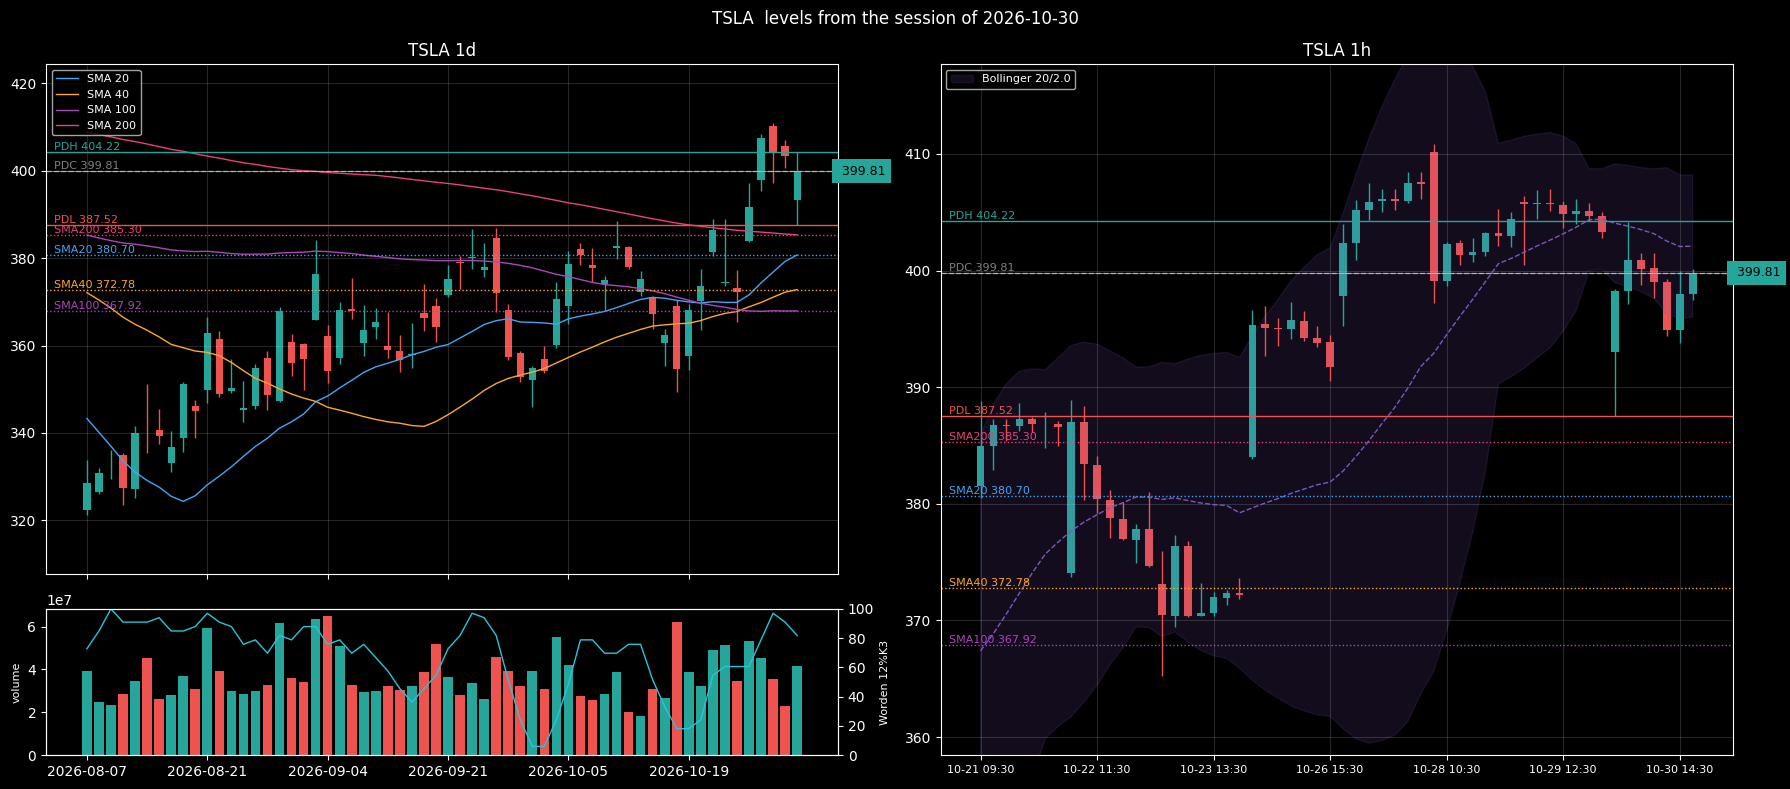

In [6]:
dashboard(TICKER)
plt.show()

## 6. Watchlist

One chart per symbol. If a symbol fails to download we print the error and move on to the next one.

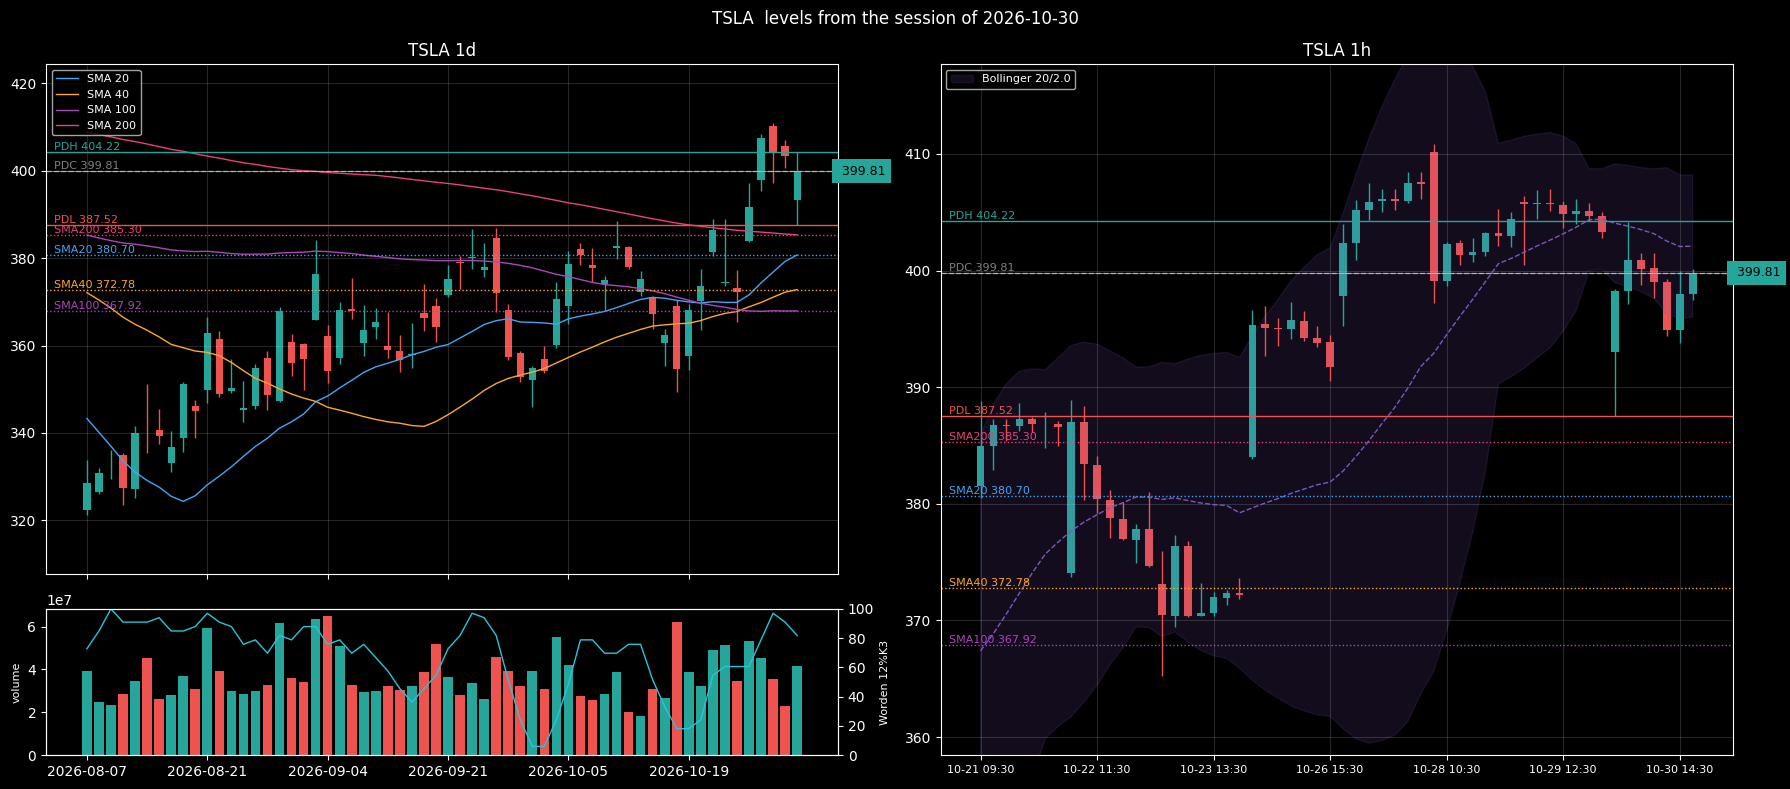

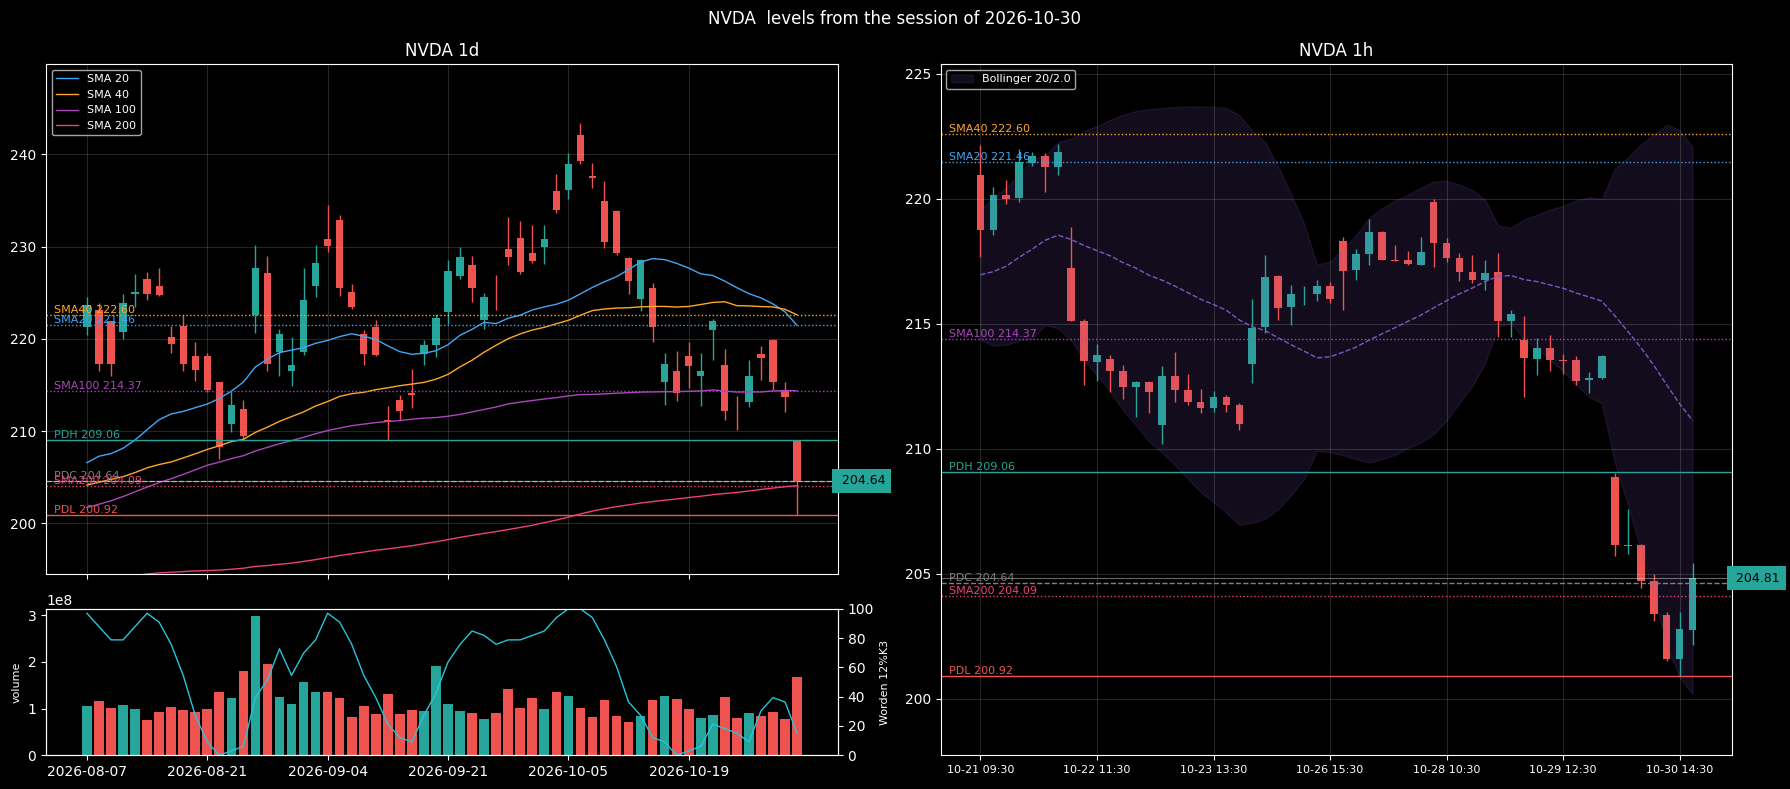

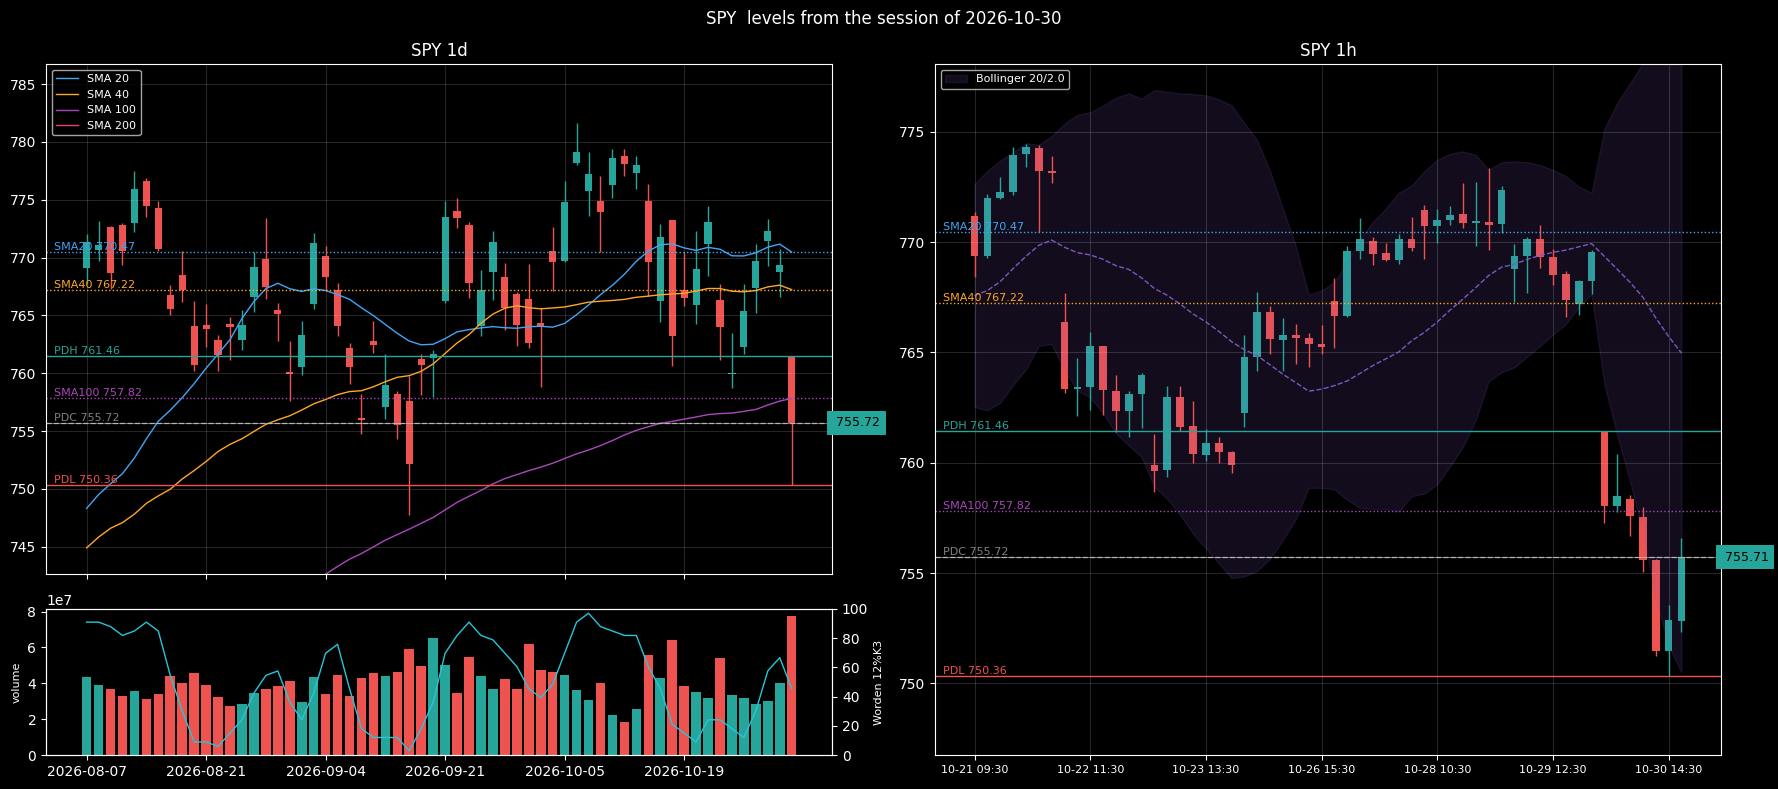

In [7]:
for symbol in WATCHLIST:
    try:
        dashboard(symbol)
        plt.show()
    except Exception as err:
        print(f"{symbol} skipped ({err})")

## 7. Auto refresh

The chart is downloaded and drawn again every few seconds. Set `MAX_REFRESHES` higher to keep it running longer.
Use Kernel then Interrupt to stop it early. Do not refresh too often or Yahoo may block the requests for a while.

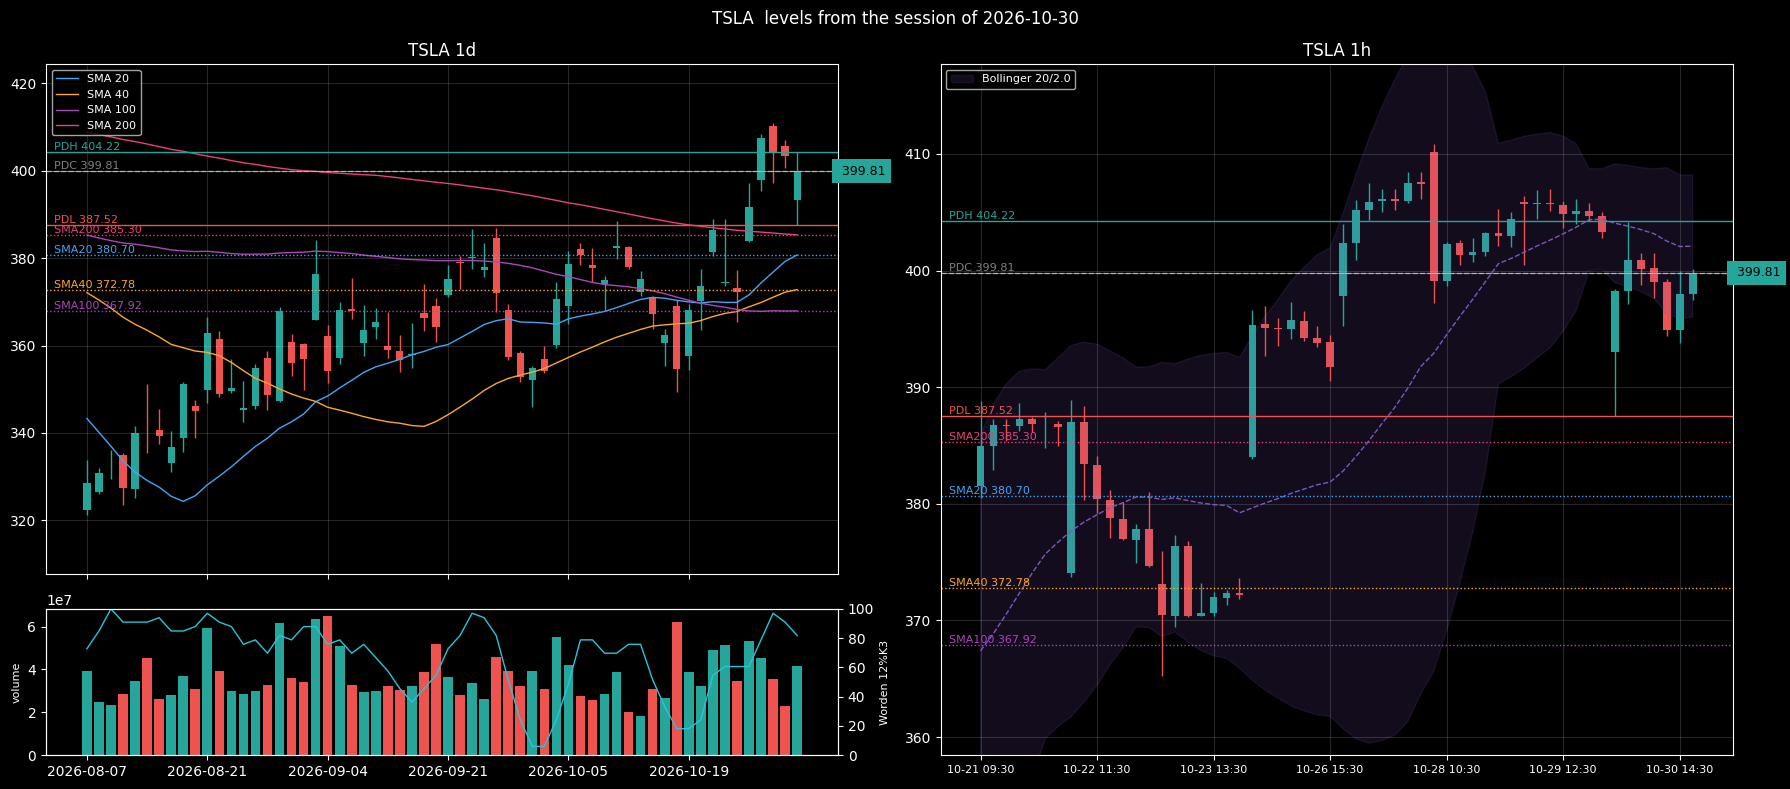

updated 14:45:30  (1 of 5)


KeyboardInterrupt: 

In [8]:
for i in range(MAX_REFRESHES):
    clear_output(wait=True)
    try:
        dashboard(TICKER)
        plt.show()
    except Exception as err:
        print(f"update failed ({err})")
    print(f"updated {pd.Timestamp.now():%H:%M:%S}  ({i + 1} of {MAX_REFRESHES})")
    if i < MAX_REFRESHES - 1:
        time.sleep(REFRESH_SECONDS)